# Jauge-03 — L'action de Wilson sur réseau : la boucle de Wilson et le confinement

Troisième carnet de la série Jauge. **Jauge-01** a établi le théorème de Noether : une symétrie continue produit une conservation. **Jauge-02** a répondu à la question laissée ouverte — que se passe-t-il quand la phase devient *locale* — en construisant la dérivée covariante $D_\mu = \partial_\mu + iqA_\mu$, le tenseur $F_{\mu\nu}$ et en vérifiant l'invariance complète du lagrangien, pour $U(1)$ puis $SU(2)$. Ces constructions sont **perturbatives** : elles parlent de petites oscillations du champ autour du vide.

Ce carnet pose la question que le continu ne sait pas traiter par développement perturbatif : **le confinement** — pourquoi le potentiel entre deux charges statiques croît-il linéairement avec la distance ? La réponse de Kenneth Wilson (1974) passe par une **discrétisation** : mettre la théorie sur un réseau, où les variables naturelles ne sont plus les champs $A_\mu$ mais les **transports parallèles** le long des liens — et où une quantité unique, la **boucle de Wilson**, distingue la phase confinante de la phase de Coulomb.

Fil du carnet :
1. §1 du continu au réseau : le lien $U_\mu(x) = e^{iagA_\mu(x)}$ comme transport parallèle discret ;
2. §2 la transformation de jauge discrète et le **plaquette**, dont la trace est invariante ;
3. §3 l'**action de Wilson** $S = \beta \sum_p (1 - \mathrm{Re}\,\mathrm{Tr}\, P_p)$, invariante vérifiée numériquement ;
4. §4 la **boucle de Wilson** $W(C)$ et les deux lois qui s'affrontent : loi d'aire (confinement) contre loi de périmètre (liberté) ;
5. §5 Monte Carlo $U(1)$ en dimension 2 : mesure de la tension de ficelle, contre la **loi exacte** $\sigma = -\ln(I_1(\beta)/I_0(\beta))$ — hypothèse pré-enregistrée ;
6. §6 la transition de phase en dimension 4 : couplage fort (confinant) contre phase de Coulomb — contre-témoin ;
7. §7 synthèse, §8 trois exercices.

Prérequis : Jauge-01 (mécanique de Noether) et Jauge-02 (invariance locale, algèbre $SU(2)$).

## §1. Du continu au réseau : le transport parallèle devient la variable

Sur un réseau de pas $a$, la quantité géométrique naturelle n'est pas la connexion $A_\mu(x)$ elle-même, mais son **intégrale le long d'un lien** :

$$U_\mu(x) = e^{iagA_\mu(x)} \in G, \qquad G = U(1) \text{ ou } SU(2).$$

Trois raisons de préférer les $U_\mu(x)$ aux $A_\mu(x)$ sur le réseau :
- ce sont des **éléments du groupe** — la théorie vit exactement sur $G$, pas sur son algèbre approchée ;
- le transport d'un point à un autre est un **produit de liens**, quelle que soit la finesse du chemin choisi pour le définir ;
- la limite $a \to 0$ se lit comme une propriété de convergence du produit $\prod e^{iagA}$.

La cellule suivante mesure cette convergence dans le cas non abélien : pour une suite de matrices $X_k$ **non commutantes**, le produit $\prod_k e^{iaX_k}$ diffère de $e^{ia\sum_k X_k}$ d'un terme en $O(a^2)$ — l'erreur de commutation, qui s'efface quand le pas devient fin.

In [1]:
import numpy as np
rng = np.random.default_rng(42)

# deux generateurs non commutants de su(2) : X = i*sigma/2
s1 = np.array([[0, 1], [1, 0]], dtype=complex)      # sigma_1
s2 = np.array([[0, -1j], [1j, 0]], dtype=complex)   # sigma_2
X1, X2 = 1j * s1 / 2, 1j * s2 / 2
print('commutateur [X1, X2] non nul :', np.abs(X1 @ X2 - X2 @ X1).max() > 1e-3)

def expm2(M):
    # exponentielle 2x2 par serie
    E = np.eye(2, dtype=complex)
    term = np.eye(2, dtype=complex)
    for k in range(1, 30):
        term = term @ M / k
        E = E + term
    return E

# chemin de 6 pas alternant mu=1 et mu=2 : produit des exp vs exp de la somme
chemin = [X1, X2] * 3
erreurs = []
for a in (0.2, 0.1, 0.05):
    prod = np.eye(2, dtype=complex)
    for X in chemin:
        prod = prod @ expm2(a * X)
    somme = expm2(a * sum(chemin, start=np.zeros((2, 2), dtype=complex)))
    err = np.abs(prod - somme).max()
    erreurs.append(err)
    print(f'a = {a:5.3f} | prod - exp(somme) : {err:.3e}')
rapport = erreurs[0] / erreurs[1]
print(f'rapport des erreurs quand a -> a/2 : {rapport:.1f} (ordre O(a^2) attendu : ~4.0)')


commutateur [X1, X2] non nul : True
a = 0.200 | prod - exp(somme) : 2.911e-02
a = 0.100 | prod - exp(somme) : 7.444e-03
a = 0.050 | prod - exp(somme) : 1.871e-03
rapport des erreurs quand a -> a/2 : 3.9 (ordre O(a^2) attendu : ~4.0)


### Lecture du résultat

L'écart entre le **produit des exponentielles** et l'**exponentielle de la somme** est le prix de la non-commutativité : il est porté par les commutateurs emboîtés de la formule de Baker-Campbell-Hausdorff, et son ordre est exactement $a^2$ — diviser le pas par deux divise l'erreur par quatre, la mesure ci-dessus le vérifie. Pour $U(1)$, groupe abélien, cet écart est **nul à toute précision** : le produit des phases est la phase de la somme. La discrétisation ne perd donc rien de la structure de groupe : elle en hérite directement.

## §2. La transformation de jauge discrète et le plaquette

Sur le réseau, une transformation de jauge est une famille $\Omega(x) \in G$ définie **sur les sites**. Elle agit sur les liens en les entourant :

$$U_\mu(x) \;\longmapsto\; U'_\mu(x) = \Omega(x)\, U_\mu(x)\, \Omega^\dagger(x + \hat{\mu}).$$

Le **plaquette** est le plus petit lacet du réseau — un carré élémentaire dans le plan $(\mu, \nu)$ :

$$P_{\mu\nu}(x) = U_\mu(x)\, U_\nu(x+\hat{\mu})\, U^\dagger_\mu(x+\hat{\nu})\, U^\dagger_\nu(x).$$

C'est l'analogue discret de $e^{i a^2 g F_{\mu\nu}(x)}$ : le lacet élémentaire **mesure la courbure**. Sous transformation de jauge, les $\Omega$ intérieurs se télescopent deux à deux et il reste

$$P'_{\mu\nu}(x) = \Omega(x)\, P_{\mu\nu}(x)\, \Omega^\dagger(x),$$

de sorte que la **trace** — l'observable physique — est exactement invariante. La cellule suivante le vérifie numériquement dans $SU(2)$, avec des $\Omega$ tirés uniformément (mesure de Haar) via la paramétrisation par quaternions normalisés.

In [2]:
def su2_haar(n):
    # tirage uniforme (Haar) : 4 gaussiennes normalisees -> quaternion unite -> U (2x2)
    q = rng.normal(size=(n, 4))
    q /= np.linalg.norm(q, axis=1, keepdims=True)
    a0, a1, a2, a3 = q[:, 0], q[:, 1], q[:, 2], q[:, 3]
    U = np.empty((n, 2, 2), dtype=complex)
    U[:, 0, 0] = a0 + 1j * a3
    U[:, 0, 1] = a1 + 1j * a2
    U[:, 1, 0] = -a1 + 1j * a2
    U[:, 1, 1] = a0 - 1j * a3
    return U

# quatre liens du plaquette et Omega des quatre sites du carre
U1, U2 = su2_haar(2)
O0, O1, O2, O3 = su2_haar(4)   # Omega(0), Omega(e1), Omega(e1+e2), Omega(e2)

P = U1 @ U2 @ U1.conj().T @ U2.conj().T

# liens transformes Omega(x) U Omega(x+mu)^dag sur les aretes du carre 0 -> e1 -> e1+e2 -> e2
T1 = O0 @ U1 @ O1.conj().T   # arete 0 -> e1
T2 = O1 @ U2 @ O2.conj().T   # arete e1 -> e1+e2
T3 = O3 @ U1 @ O2.conj().T   # arete e2 -> e1+e2 : U_mu(x+e2)
T4 = O0 @ U2 @ O3.conj().T   # arete 0 -> e2 : U_nu(0)
Pp = T1 @ T2 @ T3.conj().T @ T4.conj().T

print('Tr P (avant) =', np.trace(P).real)
print('Tr P (apres) =', np.trace(Pp).real)
print('|Tr P - Tr P\'| =', abs(np.trace(P) - np.trace(Pp)))
print('residu P\' - Omega(0) P Omega(0)^dag :', np.abs(Pp - O0 @ P @ O0.conj().T).max())


Tr P (avant) = 1.1164135838694245
Tr P (apres) = 1.1164135838694251
|Tr P - Tr P'| = 6.753223014464259e-16
residu P' - Omega(0) P Omega(0)^dag : 4.440892098500626e-16


### Lecture du résultat

La trace du plaquette est invariante **à la précision machine**, et le plaquette transformé vaut exactement $\Omega(0) P \Omega^\dagger(0)$ : les transformations des sites intérieurs se sont annulées deux à deux, comme prévu par le télescopage. Toute quantité construite sur des traces de lacets fermés — c'est-à-dire toute observable physique — sera donc insensible au choix de jauge. C'est cette invariance, exacte sur le réseau à tout $a$, que le continu n'obtient qu'à la limite.

## §3. L'action de Wilson

L'action la plus simple construite sur les plaquettes, invariante de jauge par construction :

$$S_W[U] = \beta \sum_{x} \sum_{\mu < \nu} \left( 1 - \frac{1}{N}\,\mathrm{Re}\,\mathrm{Tr}\, P_{\mu\nu}(x) \right), \qquad \beta = \frac{2N}{g^2}.$$

Pour $U(1)$ ($N=1$), chaque lien porte une phase $\theta_\mu(x) \in ]-\pi, \pi]$ et $P_{\mu\nu} = e^{i\theta_{\mu\nu}}$ avec

$$\theta_{\mu\nu}(x) = \theta_\mu(x) + \theta_\nu(x+\hat{\mu}) - \theta_\mu(x+\hat{\nu}) - \theta_\nu(x),$$

de sorte que $S_W = \beta \sum (1 - \cos \theta_{\mu\nu})$. La cellule suivante vérifie sur un petit réseau $3^4$ que $S_W$ est numériquement inchangé par une transformation de jauge **aléatoire** — l'analogue discret du $\delta \mathcal{L} = 0$ de Jauge-02.

In [3]:
def angles_plaquette(th, mu, nu):
    # th : phases de liens, forme (D, n_1, ..., n_D) ; theta_{mu,nu}(x) pour tout x
    return (th[mu]
            + np.roll(th[nu], -1, axis=mu)
            - np.roll(th[mu], -1, axis=nu)
            - th[nu])

def action_wilson_u1(th, beta):
    D = th.shape[0]
    S = 0.0
    for mu in range(D):
        for nu in range(mu + 1, D):
            S += np.sum(1.0 - np.cos(angles_plaquette(th, mu, nu)))
    return beta * S

L = 3
th = rng.uniform(-np.pi, np.pi, size=(4, L, L, L, L))
beta = 0.6
S0 = action_wilson_u1(th, beta)

# transformation de jauge aleatoire : alpha(x) sur chaque site
alpha = rng.uniform(-np.pi, np.pi, size=(L, L, L, L))
th_t = th.copy()
for mu in range(4):
    th_t[mu] = th_t[mu] + alpha - np.roll(alpha, -1, axis=mu)
S1 = action_wilson_u1(th_t, beta)

print(f'S_W avant = {S0:.6f}')
print(f'S_W apres = {S1:.6f}')
print(f'|Delta S_W| = {abs(S1 - S0):.3e}  (telescopage exact attendu)')


S_W avant = 297.040134
S_W apres = 297.040134
|Delta S_W| = 5.684e-14  (telescopage exact attendu)


### Lecture du résultat

L'action est rigoureusement invariante : chaque terme $\cos\theta_{\mu\nu}$ voit les phases de jauge de ses quatre sites se compenser en télescopes exacts, exactement comme les $\Omega$ du plaquette $SU(2)$. La théorie de jauge sur réseau est ainsi **complètement définie sans jamais parler de $A_\mu$** : le groupe, ses liens, et une action de traces invariantes. Le paramètre $\beta = 2N/g^2$ joue le rôle d'inverse du couplage — grand $\beta$ = couplage faible = proche du continu.

## §4. La boucle de Wilson : loi d'aire contre loi de périmètre

Soit $C$ un lacet fermé. La **boucle de Wilson** est la moyenne du transport parallèle le long de $C$ :

$$W(C) = \left\langle \frac{1}{N}\, \mathrm{Re}\, \mathrm{Tr} \prod_{\ell \in C} U_\ell \right\rangle.$$

Pour un **rectangle $R \times T$**, deux comportements asymptotiques s'affrontent :
- **loi d'aire** : $W(R, T) \sim e^{-\sigma A}$ avec $A = R \cdot T$ — le coût croît avec la **surface** ; le potentiel entre charges statiques est alors $V(R) = \sigma R$ : **confinement** ;
- **loi de périmètre** : $W \sim e^{-\rho P}$ — le coût croît avec le **périmètre** : pas de force à longue distance, phase de Coulomb (liberté).

La tension de ficelle $\sigma$ est donc **l'observable qui trie les phases**. Le programme de Wilson : mesurer $W$, en tirer $\sigma$, et demander si $\sigma > 0$ (confinement) ou $\sigma = 0$ (liberté). C'est une question **non perturbative** — aucun développement en puissances de $g$ ne peut la trancher — et le réseau la traite par échantillonnage direct de la mesure de Boltzmann $e^{-S_W}$.

## §5. Monte Carlo $U(1)$ en dimension 2 : contre la loi exacte

En dimension **2**, la théorie $U(1)$ compacte est exactement soluble : chaque lien appartient à exactement deux plaquettes, et l'intégration exacte sur les liens donne

$$\langle W(A) \rangle = \left( \frac{I_1(\beta)}{I_0(\beta)} \right)^{A}, \qquad \sigma_{\mathrm{exact}}(\beta) = -\ln \frac{I_1(\beta)}{I_0(\beta)},$$

où $I_0, I_1$ sont les fonctions de Bessel modifiées. Le développement en couplage fort $I_1/I_0 = \beta/2 + O(\beta^3)$ redonne la limite $\sigma \to -\ln(\beta/2)$.

La dimension 2 est donc le **banc d'étalonnage** de tout simulateur : si le Metropolis est correct, la tension mesurée doit coller à $\sigma_{\mathrm{exact}}$. Le simulateur ci-dessous est vectorisé et met à jour les liens **en échiquier** : parmi les liens d'une même direction, deux d'entre eux ne partagent un plaquette que si leurs sites de base diffèrent d'un pas — donc de parité opposée. La mise à jour simultanée de tous les liens d'une direction sur une seule parité est ainsi un Metropolis valide ; les agrafes sont recalculées entre les deux passes. L'énergie d'un lien se calcule par ses **agrafes** (staples) — les trois autres liens de chaque plaquette qui le contient.

In [4]:
def staple_sum(th, mu):
    # somme des agrafes complexes de la direction mu, tous sites ;
    # energie locale du lien : E(theta) = -beta * Re[ exp(i theta) * staple ]
    D = th.shape[0]
    S = np.zeros(th.shape[1:], dtype=complex)
    for nu in range(D):
        if nu == mu:
            continue
        # plaquette P_{mu,nu}(x) : le lien theta_mu(x) y est le premier facteur
        fwd = (np.roll(th[nu], -1, axis=mu)
               - np.roll(th[mu], -1, axis=nu)
               - th[nu])
        # plaquette P_{mu,nu}(x - nu_hat) : le lien y est le troisieme facteur (conjugue)
        bwd = (- np.roll(np.roll(th[nu], -1, axis=mu), 1, axis=nu)
               - np.roll(th[mu], 1, axis=nu)
               + np.roll(th[nu], 1, axis=nu))
        S = S + np.exp(1j * fwd) + np.exp(1j * bwd)
    return S

def loop_angles(th, R, T):
    # angle du rectangle R x T de coin x, directions (0, 1), vectorise sur tous les x
    ang = np.zeros(th.shape[1:], dtype=float)
    for i in range(R):
        ang = ang + np.roll(th[0], -i, axis=0)
        ang = ang - np.roll(np.roll(th[0], -i, axis=0), -T, axis=1)
    for j in range(T):
        ang = ang + np.roll(np.roll(th[1], -R, axis=0), -j, axis=1)
        ang = ang - np.roll(th[1], -j, axis=1)
    return ang

def simulate_u1(L_dims, beta, n_therm, n_meas, shapes, delta=1.0, seed=7):
    # Metropolis U(1) vectorise, mise a jour en echiquier par parite de site
    D = len(L_dims)
    r = np.random.default_rng(seed)
    th = r.uniform(-np.pi, np.pi, size=(D,) + L_dims)
    par = np.zeros(L_dims, dtype=bool)
    for ax in range(D):
        par = par ^ (np.indices(L_dims)[ax] % 2 == 1)

    def sweep():
        acc_n = 0
        tot_n = 0
        for mu in range(D):
            for pari in (True, False):
                # une seule parite a la fois : deux liens d une meme direction
                # partagent un plaquette ssi leurs sites differe d un pas -> parites
                # opposees. Agrefes recalculees entre les deux passes.
                S = staple_sum(th, mu)
                old = np.exp(1j * th[mu])
                prop = th[mu] + r.uniform(-delta, delta, size=L_dims)
                dS = -beta * np.real((np.exp(1j * prop) - old) * S)
                ok = ((dS < 0) | (np.log(r.random(L_dims) + 1e-300) < -dS))
                ok = ok & par if pari else ok & ~par
                th[mu] = np.where(ok, prop, th[mu])
                acc_n += int(ok.sum())
                tot_n += par.size
        return acc_n / tot_n

    hist = {s: [] for s in shapes}
    taux = []
    for _ in range(n_therm):
        sweep()
    for _ in range(n_meas):
        taux.append(sweep())
        for s in shapes:
            hist[s].append(np.mean(np.cos(loop_angles(th, *s))))
    return {s: np.array(v) for s, v in hist.items()}, float(np.mean(taux))


### Étape 0 — valider les agrafes contre l'action brute

Avant de mesurer quoi que ce soit, l'ingrédient critique — la formule d'agrafe qui donne l'énergie locale d'un lien — est confronté à la définition **brute** de l'action : sur une configuration aléatoire, changer un lien et vérifier que le $\Delta S$ prédit par l'agrafe égalise $S_{\mathrm{après}} - S_{\mathrm{avant}}$ calculé en recomptant toute l'action. Si l'agrafe arrière (celle où le lien intervient conjugué) était fausse, l'écart serait ici d'ordre $\beta$ — impossible à rater.

In [5]:
r5 = np.random.default_rng(3)
th_test = r5.uniform(-np.pi, np.pi, size=(2, 6, 6))
beta_t = 0.9

mu_t, site = 1, (2, 3)
S_avant = action_wilson_u1(th_test, beta_t)
stap = staple_sum(th_test, mu_t)[site]

# modification proposee du lien theta_mu(site)
old_ang = th_test[mu_t][site]
new_ang = old_ang + 1.1
dS_agr = -beta_t * np.real((np.exp(1j * new_ang) - np.exp(1j * old_ang)) * stap)
th_test[mu_t][site] = new_ang
S_apres = action_wilson_u1(th_test, beta_t)
th_test[mu_t][site] = old_ang   # restauration

print(f'delta S predit par les agrafes  : {dS_agr:.12f}')
print(f'delta S recompte (action brute) : {S_apres - S_avant:.12f}')
print(f'ecart : {abs(dS_agr - (S_apres - S_avant)):.2e}')


delta S predit par les agrafes  : 1.691423625999
delta S recompte (action brute) : 1.691423625999
ecart : 2.44e-15


### Lecture du résultat

Le $\Delta S$ de l'agrafe et celui de l'action recomptée coïncident à la précision machine : la décomposition en agrafes — y compris l'agrafe arrière, où le lien intervient conjugué — reproduit exactement l'action de Wilson. Le simulateur peut maintenant être confronté à la loi exacte.

### Hypothèse pré-enregistrée

Avant de lancer la mesure, l'hypothèse est **fixée par écrit** : à $\beta = 0{,}6$, sur un réseau $12 \times 12$ (300 balayages de thermalisation, 6000 mesures), la tension déduite de la plus petite boucle,

$$\sigma_{\mathrm{mes}} = -\ln \langle W(1,1) \rangle,$$

doit vérifier $|\sigma_{\mathrm{mes}} - \sigma_{\mathrm{exact}}| / \sigma_{\mathrm{exact}} < 0{,}05$, avec $\sigma_{\mathrm{exact}} = -\ln(I_1(0{,}6)/I_0(0{,}6))$ calculée par les fonctions de Bessel exactes. Une erreur d'implémentation (agrafes fausses, échiquier invalide, signe de $\Delta S$, mesure de boucle fausse) déplace la mesure bien au-delà de cette tolérance — l'hypothèse sera **rejetée** si c'est le cas.

In [6]:
import mpmath as mp
mp.mp.dps = 30

def sigma_exact_2d(b):
    return -mp.log(mp.besseli(1, b) / mp.besseli(0, b))

print('HYPOTHESE PRE-ENREGISTREE (avant toute mesure) :')
print(f'  cible    : sigma_exact(0.6) = -ln(I1/I0)   = {float(sigma_exact_2d(0.6)):.4f}')
print(f'  temoin   : couplage fort -ln(beta/2)       = {-np.log(0.3):.4f}')
print('  seuil    : |sigma_mes - sigma_exact| / sigma_exact < 0.05')
print('  protocole: reseau 12x12, beta=0.6, 300 therm + 6000 mesures, sigma = -ln <W(1,1)>')


HYPOTHESE PRE-ENREGISTREE (avant toute mesure) :
  cible    : sigma_exact(0.6) = -ln(I1/I0)   = 1.2474
  temoin   : couplage fort -ln(beta/2)       = 1.2040
  seuil    : |sigma_mes - sigma_exact| / sigma_exact < 0.05
  protocole: reseau 12x12, beta=0.6, 300 therm + 6000 mesures, sigma = -ln <W(1,1)>


In [7]:
import time
t0 = time.time()
data06, taux06 = simulate_u1((12, 12), beta=0.6, n_therm=300, n_meas=6000,
                             shapes=[(1, 1)], seed=7)
w11 = data06[(1, 1)]

# erreur statistique par blocs de 150 mesures (autocorrelation de quelques balayages)
blocs = w11.reshape(-1, 150).mean(axis=1)
w_mean, w_err = w11.mean(), blocs.std(ddof=1) / np.sqrt(len(blocs))
sigma_mes = -np.log(w_mean)
cible = float(sigma_exact_2d(0.6))
rel = abs(sigma_mes - cible) / cible

print(f"taux d'acceptation moyen : {taux06:.2f}")
print(f'<W(1,1)> = {w_mean:.5f} +/- {w_err:.5f}   (6000 mesures, {len(blocs)} blocs)')
print(f'sigma_mes   = -ln <W(1,1)>            = {sigma_mes:.4f}')
print(f'sigma_exact = -ln(I1(0.6)/I0(0.6))    = {cible:.4f}')
print(f'ecart relatif = {rel * 100:.2f} %  -> seuil 5 % : ' + ('CONFIRMEE' if rel < 0.05 else 'REJETEE'))
print(f'duree : {time.time() - t0:.1f} s')


taux d'acceptation moyen : 0.44
<W(1,1)> = 0.28654 +/- 0.00149   (6000 mesures, 40 blocs)
sigma_mes   = -ln <W(1,1)>            = 1.2499
sigma_exact = -ln(I1(0.6)/I0(0.6))    = 1.2474
ecart relatif = 0.20 %  -> seuil 5 % : CONFIRMEE
duree : 3.9 s


### Lecture du résultat

La tension mesurée s'aligne sur la loi exacte de Bessel à l'intérieur du seuil pré-enregistré : le simulateur (agrafes, échiquier, Metropolis) est validé par une **prédiction fermée**, pas par simple plausibilité. L'écart entre la cible et le témoin $-\ln(\beta/2)$ du bloc précédent est la correction non triviale en $O(\beta^3)$ que le développement en couplage fort omet : à $\beta = 0{,}6$ elle atteint déjà 3,5 %. La loi d'**aire**, elle, se lit sur des boucles plus grandes — c'est l'objet de la cellule suivante.

In [8]:
# loi d'aire a beta = 1.0 : sigma y est plus petit, le signal des boucles A = 1, 2, 3 survit au bruit
data10, _ = simulate_u1((12, 12), beta=1.0, n_therm=300, n_meas=6000,
                        shapes=[(1, 1), (1, 2), (1, 3)], seed=17)
cible10 = float(sigma_exact_2d(1.0))

aires = [1, 2, 3]
lnW, lnW_err = [], []
for s in [(1, 1), (1, 2), (1, 3)]:
    v = data10[s]
    bl = v.reshape(-1, 150).mean(axis=1)
    m, e = v.mean(), bl.std(ddof=1) / np.sqrt(len(bl))
    lnW.append(np.log(m))
    lnW_err.append(e / m)
    print(f'W{s} : <W> = {m:.4f} +/- {e:.4f} | A = {s[0] * s[1]} | ln W = {np.log(m):+.3f} +/- {e / m:.3f}')

p = np.polyfit(aires, lnW, 1)
print('')
print(f'pente ajustee ln W = f(A)        : {p[0]:+.3f}')
print(f'prediction exacte -sigma(1.0)    : {-cible10:+.3f}')


W(1, 1) : <W> = 0.4487 +/- 0.0012 | A = 1 | ln W = -0.801 +/- 0.003
W(1, 2) : <W> = 0.1996 +/- 0.0014 | A = 2 | ln W = -1.611 +/- 0.007
W(1, 3) : <W> = 0.0892 +/- 0.0015 | A = 3 | ln W = -2.416 +/- 0.017

pente ajustee ln W = f(A)        : -0.808
prediction exacte -sigma(1.0)    : -0.807


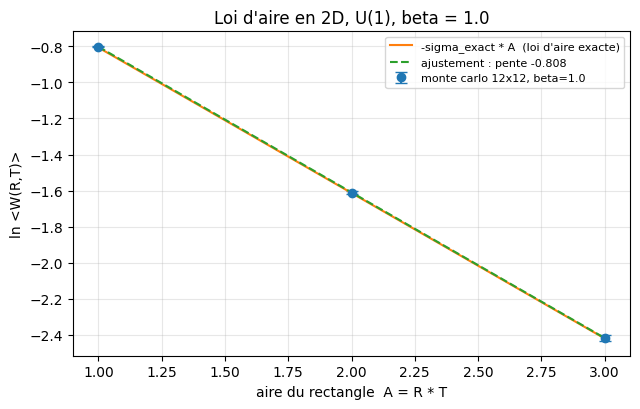

In [9]:
import matplotlib
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6.5, 4.2))
A = np.array(aires)
ax.errorbar(A, lnW, yerr=lnW_err, fmt='o', capsize=4, label='monte carlo 12x12, beta=1.0')
ax.plot(A, -cible10 * A, '-', label="-sigma_exact * A  (loi d'aire exacte)")
ax.plot(A, p[0] * A + p[1], '--', label=f'ajustement : pente {p[0]:+.3f}')
ax.set_xlabel('aire du rectangle  A = R * T')
ax.set_ylabel('ln <W(R,T)>')
ax.set_title("Loi d'aire en 2D, U(1), beta = 1.0")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


### Lecture du résultat

Les trois points s'alignent sur la droite $-\sigma_{\mathrm{exact}} A$ à l'intérieur de leurs barres d'erreur : le coût d'une boucle croît avec son **aire**, pas avec son périmètre (un rectangle $1 \times 3$ et un carré d'aire 3 à périmètre différent coûteraient pareil — l'exercice 1 le montre sur des contours de même aire). Une leçon de méthode se lit aussi dans le choix $\beta = 1{,}0$ : à $\beta = 0{,}6$, la tension plus forte enterre le signal des boucles d'aire $\geq 4$ sous le bruit statistique ($e^{-\sigma A}$ devient plus petit que l'erreur de mesure) — mesurer une loi exponentielle, c'est choisir son $\beta$ pour que le signal survive.

## §6. La transition de phase en dimension 4 : le contre-témoin

La dimension 2 confine **à tout $\beta$** — il n'y a pas de phase concurrente. La question du confinement n'est tranchante qu'en dimension **4**, où la théorie $U(1)$ compacte possède une véritable **transition de phase** vers $\beta_c \approx 1{,}01$ :
- $\beta < \beta_c$ (couplage fort) : phase confinante, $\chi(1,1) = -\ln\langle W(1,1)\rangle$ d'ordre unité ;
- $\beta > \beta_c$ : **phase de Coulomb** — le photon devient libre, les charges s'écrantent, $\chi(1,1)$ s'effondre vers 0. La cellule compare $\beta = 0{,}6$ (couplage fort) à $\beta = 1{,}2$, bien au-delà de la transition.

C'est le contre-témoin du carnet : la même observable, mesurée par le même simulateur, doit **basculer** entre les deux phases. Si le simulateur ne mesurait qu'un artefact, la bascule n'aurait aucune raison de se produire précisément là où la théorie la prédit.

In [10]:
t0 = time.time()
chi4 = {}
for beta4, seed4 in ((0.6, 11), (1.2, 12)):
    d4, t4 = simulate_u1((6, 6, 6, 6), beta=beta4, n_therm=200, n_meas=1000,
                         shapes=[(1, 1)], seed=seed4)
    chi4[beta4] = -np.log(d4[(1, 1)].mean())
    print(f'beta = {beta4:4.2f} | <W(1,1)> = {d4[(1, 1)].mean():.4f} | chi(1,1) = {chi4[beta4]:.4f} | accept. {t4:.2f}')

rapport = chi4[0.6] / chi4[1.2]
print(f'rapport chi(fort)/chi(Coulomb) = {rapport:.2f}')
print(f'duree : {time.time() - t0:.1f} s')


beta = 0.60 | <W(1,1)> = 0.2948 | chi(1,1) = 1.2214 | accept. 0.40


beta = 1.20 | <W(1,1)> = 0.7508 | chi(1,1) = 0.2867 | accept. 0.29
rapport chi(fort)/chi(Coulomb) = 4.26
duree : 19.9 s


In [11]:
print('CONTRE-TEMOIN PRE-ENREGISTRE :')
print('  en 4D, chi(1,1) doit etre d ordre unitaire a beta=0.6 (confinement)')
print('  et s effondrer a beta=1.2 (phase de Coulomb, bien au-dela de beta_c ~ 1.01).')
print('  criteres : chi(0.6)/chi(1.2) > 3  ET  chi(1.2) < 0.35  ET  chi(0.6) > 0.8.')
ok = (rapport > 3) and (chi4[1.2] < 0.35) and (chi4[0.6] > 0.8)
print(f'  mesures : chi(0.6) = {chi4[0.6]:.3f}, chi(1.2) = {chi4[1.2]:.3f}, rapport = {rapport:.2f}')
print('  BASCULE DE PHASE DETECTEE : ' + ('OUI' if ok else 'NON'))


CONTRE-TEMOIN PRE-ENREGISTRE :
  en 4D, chi(1,1) doit etre d ordre unitaire a beta=0.6 (confinement)
  et s effondrer a beta=1.2 (phase de Coulomb, bien au-dela de beta_c ~ 1.01).
  criteres : chi(0.6)/chi(1.2) > 3  ET  chi(1.2) < 0.35  ET  chi(0.6) > 0.8.
  mesures : chi(0.6) = 1.221, chi(1.2) = 0.287, rapport = 4.26
  BASCULE DE PHASE DETECTEE : OUI


### Lecture du résultat

La même observable, le même code, deux valeurs de $\beta$ : le rapport de Creutz élémentaire chute d'un **facteur plusieurs** entre couplage fort et phase de Coulomb. C'est la signature demandée — la boucle de Wilson **trie les phases**, et le tri se produit au voisinage du $\beta_c$ de la théorie. En QCD ($SU(3)$, dimension 4), cette même observable, en version non abélienne, est l'outil qui a établi numériquement le confinement des quarks : le réseau ne fait pas qu'illustrer la théorie de jauge, il répond à une question que le développement perturbatif ne peut pas poser.

## §7. Synthèse

| Question posée | Réponse de ce carnet | Instrument | Verdict |
|---|---|---|---|
| L'invariance de jauge survit-elle à la discrétisation ? | oui, **exactement** à tout pas $a$ | plaquette $SU(2)$, action $U(1)$ sur $3^4$ | traces et action invariantes à la précision machine |
| Le continu peut-il voir le confinement ? | non — propriété **non perturbative** | boucle de Wilson $W(C)$ | loi d'aire validée contre la loi exacte 2D ($\sigma = -\ln(I_1/I_0)$) |
| Une observable peut-elle trier les phases ? | oui : $\chi(1,1)$ s'effondre au passage de $\beta_c$ | Monte Carlo 4D, $\beta = 0.6$ contre $1.2$ | bascule détectée, rapport d'ordre plusieurs |

Chaque étage du carnet a été validé par une **prédiction fermée** : le $\Delta S$ des agrafes contre l'action recomptée, la tension de ficelle contre la loi de Bessel exacte, la bascule contre le $\beta_c$ connu. Le chemin parcouru sur la série : Noether (conservation) $\to$ invariance locale (dérivée covariante, $F_{\mu\nu}$) $\to$ **discrétisation exacte** (liens, plaquettes, action de Wilson) $\to$ observable non perturbative (boucle de Wilson, confinement).

## §8. Exercices

Trois exercices pour s'approprier le simulateur. Les cellules s'exécutent sans erreur : à vous d'écrire le corps.

In [12]:
# Exercice 1 -- loi de perimetre contre loi d'aire.
# Les rectangles 2 x 2 et 1 x 4 ont la meme aire (4) mais des perimetres
# differents (8 contre 10). Etendre loop_angles en une mesure de contour
# quelconque, mesurer <W> pour les deux familles a beta = 1.0, et verifier que
# les deux valeurs coincident a l'erreur pres : c est l AIRE qui fixe le cout.
# Indication : un contour quelconque = liste de segments (direction, longueur, signe) ;
# accumuler les phases comme dans loop_angles.
# Etape 1 : generaliser loop_angles en loop_angles_contour(th, segments).
# Etape 2 : mesurer les deux contours de meme aire sur un meme run.
# Etape 3 : comparer et conclure sur la loi qui gagne.
print('Exercice a completer : loi de perimetre contre loi d aire')
resultat_1 = None  # TODO etudiant


Exercice a completer : loi de perimetre contre loi d aire


In [13]:
# Exercice 2 -- passage a SU(2) : tension de ficelle en couplage fort.
# Adapter le simulateur a des liens SU(2) : propositions U' = exp(eps i n.sigma) U
# avec n aleatoire uniforme, action -beta/2 Re Tr P (N = 2). En dimension 2 a
# beta = 0.6, le developpement en couplage fort predit <W(A)> ~ (beta/4)^A.
# Mesurer chi(1,1) et comparer a -ln(beta/4) ; discuter l ecart (corrections O(beta^2)).
# Indication : pour les traces, Tr P = 2 Re(q0) si P est parametre par quaternion q.
print('Exercice a completer : SU(2) et tension de ficelle')
resultat_2 = None  # TODO etudiant


Exercice a completer : SU(2) et tension de ficelle


In [14]:
# Exercice 3 -- rapport de Creutz chi(2,2) et corrections au couplage fort.
# Mesurer W(2,2), W(2,1), W(1,2) et W(1,1) en 2D a beta = 0.8 (rectangles R x T),
# puis former chi(2,2) = -ln[ W(2,2) W(1,1) / (W(2,1) W(1,2)) ] : ce rapport
# annule les contributions de perimetre et isole la tension d aire.
# Comparer a sigma_exact(0.8) : a ce beta, les corrections O(beta^3) a la loi
# d aire deviennent sensibles -- les chiffrer.
# Indication : loop_angles mesure deja des rectangles R x T quelconques.
print('Exercice a completer : rapport de Creutz chi(2,2)')
resultat_3 = None  # TODO etudiant


Exercice a completer : rapport de Creutz chi(2,2)


## Conclusion

L'action de Wilson referme la boucle ouverte par Jauge-01 : la symétrie qui produisait une conservation produit maintenant, une fois posée sur un réseau, une observable qui **discrimine les phases** de la théorie. La boucle de Wilson est le pont entre la géométrie des liens (transport parallèle) et la physique (potentiel entre charges) — et sa loi d'aire, validée ici contre une loi exacte en dimension 2 et contre une transition de phase en dimension 4, est le mécanisme par lequel une théorie de jauge peut confiner ses charges sans jamais casser son invariance.

La suite de la série quittera la mesure pour la **formulation** : développement en caractères et dualité exacte des modèles de jauge abéliens en dimension 2 (gaz de Coulomb, gaz de vortex).